In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [2]:
# Fetch historical stock data
def get_stock_data(ticker, start='2023-01-01', end='2024-01-01'):
    data = yf.download(ticker, start=start, end=end)
    return data

In [3]:
# Calculate RSI (Relative Strength Index)
def calculate_rsi(data, window=14):
    delta = data['Close'].diff(1)
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()

    RS = gain / loss
    RSI = 100 - (100 / (1 + RS))
    data['RSI'] = RSI
    return data

In [4]:
# Prepare dataset for AI model
def prepare_data(data):
    data['Target'] = np.where(data['Close'].shift(-1) > data['Close'], 1, 0)  # 1 = Price Up, 0 = Price Down
    data = data.dropna()  # Remove NaN values
    return data[['RSI']], data['Target']  # Features (X), Labels (y)

In [5]:
# Train Machine Learning Model
def train_model(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    print("Model Accuracy:", accuracy_score(y_test, y_pred))
    return model

In [6]:
# Predict next price movement
def predict_next_move(model, data):
    last_rsi = data['RSI'].iloc[-1]  # Get latest RSI value
    prediction = model.predict([[last_rsi]])
    return "UP" if prediction[0] == 1 else "DOWN"


In [7]:
# Main execution
ticker = "AAPL"  # Change this to any stock symbol
data = get_stock_data(ticker)
data = calculate_rsi(data)
X, y = prepare_data(data)

model = train_model(X, y)
prediction = predict_next_move(model, data)

print(f"Next Price Movement Prediction for {ticker}: {prediction}")


YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed

Model Accuracy: 0.3541666666666667
Next Price Movement Prediction for AAPL: DOWN


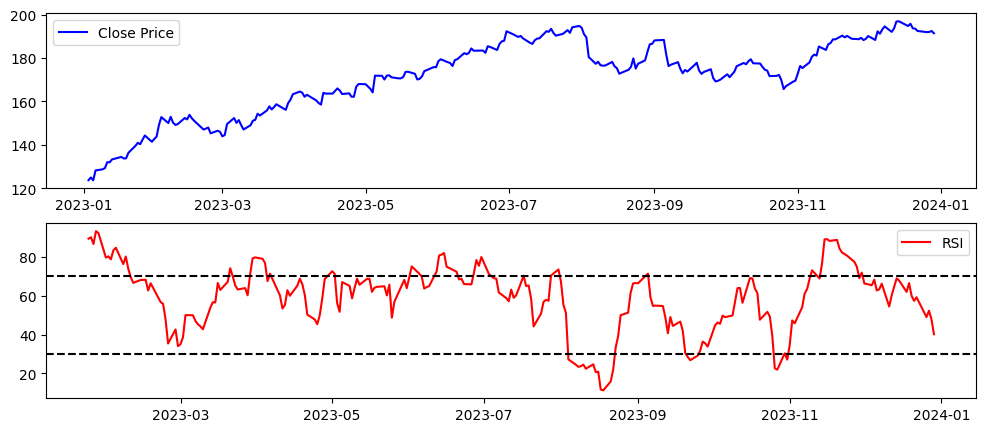

In [8]:

# Plot RSI and Close Price
plt.figure(figsize=(12,5))
plt.subplot(2, 1, 1)
plt.plot(data['Close'], label="Close Price", color='blue')
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(data['RSI'], label="RSI", color='red')
plt.axhline(70, linestyle="--", color="black")  # Overbought Level
plt.axhline(30, linestyle="--", color="black")  # Oversold Level
plt.legend()
plt.show()
